In [ ]:
import sys,os
sys.path.append('../../')

os.environ["JAX_PLATFORMS"] = "cpu"
from collections import defaultdict
import numpy as np
import matplotlib.pyplot as plt

from information_imbalance_module import (normalized_L2_distance, 
                                          hamming_distance, 
                                          build_mutual_k_NN_alignment, 
                                          build_information_imbalance,
                                          separate_samples,
                                          pairwise_distances,
                                          mapped_compute_ranks,
                                          mapped_relative_ranks,
                                          )
import jax,jax.numpy as jnp
from utils import (bf16_torch_to_jax, 
                   flatten_tokens_features, 
                   list_folder, 
                   binarize, 
                   clip,
                   makefolder,
                   )
import pickle
from tqdm import tqdm
import torch
# from datapaths import *
# import argparse
# from II_santiago import collect_data

ModuleNotFoundError: No module named 'datapaths'

In [ ]:
N_list = jnp.arange(100,1000,50,dtype=int)
Ns_list = [1000]
seed_list = np.arange(0, 10,dtype=int)
Nbits_list = [0]
k_II = 1

for N_id,N in enumerate(N_list):
  IIs = np.zeros(shape=(len(seed_list),
                      len(Ns_list),
                      len(Nbits_list),
                      2)
              )
  print(f'{N=}',flush=True)
  for Ns_id,Ns in enumerate(Ns_list):
    for Nbits_id,Nbits in enumerate(Nbits_list):
      distance_fn = normalized_L2_distance if Nbits == 0 else hamming_distance
      key = jax.random.key(42)
      key, subkey = jax.random.split(key)
      information_imbalance_fn = build_information_imbalance(key=subkey, 
                                                            sample_size=Ns, 
                                                            distance_fn=distance_fn,
                                                            k=k_II)                                                        
      for seed in seed_list:
        X = np.random.normal(loc=0, scale=1, size=(Ns, N))
        k = N   # Number of additional random features
        random_features = np.random.normal(loc=0, scale=1, size=(Ns,k))
        Y = np.concatenate((random_features,X), axis=1)
        if Nbits == 1:
          Y = binarize(Y)
          X = binarize(X)
        IIs[seed,Ns_id,Nbits_id,:] = information_imbalance_fn(X, Y)
        outputfolder = makefolder(base='results/',
                                  create_folder=True,
                                  N=N,
                                  Ns=Ns,
                                  Nbits=Nbits,
                                  k_II=k_II,
                                  )
      np.savetxt(outputfolder + 'IIs.txt', IIs[:,Ns_id,Nbits_id])

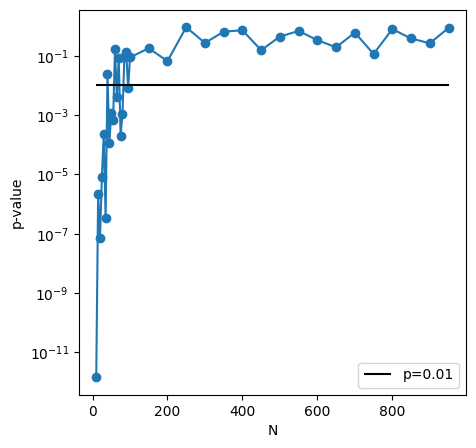

In [39]:
from scipy.stats import ttest_ind
"""The t-test quantifies the difference between the arithmetic means of the two samples. 
The p-value quantifies the probability of observing as or more extreme values assuming 
the null hypothesis, that the samples are drawn from populations with the same population 
means, is true. 
A p-value larger than a chosen threshold (e.g. 5% or 1%) indicates that our 
observation is not so unlikely to have occurred by chance. Therefore, we do not reject the 
null hypothesis of equal population means. If the p-value is smaller than our threshold, 
then we have evidence against the null hypothesis of equal population means.
"""
Ns0 = 1000
p_values = np.zeros(shape=(len(N_list),))

N_list = jnp.arange(10,100,5,dtype=int)
N_list = jnp.concatenate(jnp.array([N_list,
                                    jnp.arange(100,1000,50,dtype=int)])
                        )

for N_id,N in enumerate(N_list):
    Ns = Ns0
    outputfolder = makefolder(base='results/',
                              create_folder=False,
                              N=N,
                              Ns=Ns,
                              Nbits=Nbits,
                              k_II=k_II,
                              )
    IIs = np.loadtxt(outputfolder + 'IIs.txt')
    p_values[N_id] = ttest_ind(IIs[:,0], 
                        IIs[:,1], 
                        equal_var=False)[1]


p0 = 0.01
fig,ax = plt.subplots(1, 1, figsize=(5, 5))
ax.plot(N_list, p_values, marker='o')
ax.set_xlabel('N')
ax.set_ylabel('p-value')
ax.set_yscale('log')
ax.hlines(y=p0, xmin=N_list[0], xmax=N_list[-1],color='black',label=f'p={p0}')
ax.legend()
plt.show()

In [ ]:
mu = IIs.mean(axis=0)
std  = IIs.std(axis=0)

fig,ax = plt.subplots(1, 1, figsize=(5, 5))

for Nbits_id,Nbits in enumerate(Nbits_list):
  for II_id in range(2):
    lbl_II = f' X-->Y' if II_id == 0 else f' Y-->X' 
    ax.plot(seed_list, IIs[:,Ns_id,Nbits_id,II_id], label=f'{lbl_II} | {Nbits}', marker='o')
ax.legend()
plt.show()